In [ ]:

import h5py

file_path = (
    r"E:\1Personal\New\科研起步\large_genetic_perturbation_20260909"
    r"\02_kolf_ipsc\KOLF_ALPHA_counts.h5ad"
)

with h5py.File(file_path, "r") as f:
    print("顶层结构：", list(f.keys()))

    # 只读取 obs 和 var 的字段名，不读取表达矩阵
    for group_name in ["obs", "var"]:
        print(f"\n{'=' * 40}\n{group_name} 字段")

        group = f[group_name]
        print(list(group.keys()))

    print("\nX 的存储结构：")
    if "X" in f:
        print("类型：", f["X"].attrs.get("encoding-type", "unknown"))
        print("子节点：", list(f["X"].keys()) if isinstance(f["X"], h5py.Group) else "dataset")
        if isinstance(f["X"], h5py.Group):
            for key in ["shape", "encoding-type", "encoding-version"]:
                print(key, f["X"].attrs.get(key))


In [ ]:

import h5py
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

file_path = (
    r"E:\1Personal\New\科研起步\large_genetic_perturbation_20260909"
    r"\02_kolf_ipsc\KOLF_ALPHA_counts.h5ad"
)

# 从 h5ad 中只提取指定的 obs 字段
def read_obs_column(group, col):
    node = group[col]

    if isinstance(node, h5py.Dataset):
        values = node[:]
        if values.dtype.kind in ("S", "O"):
            values = [
                x.decode("utf-8") if isinstance(x, bytes) else x
                for x in values
            ]
        return pd.Series(values)

    if isinstance(node, h5py.Group):
        codes = node["codes"][:]
        categories = node["categories"][:]
        categories = [
            x.decode("utf-8") if isinstance(x, bytes) else x
            for x in categories
        ]

        values = np.full(len(codes), None, dtype=object)
        valid = codes >= 0
        values[valid] = np.asarray(categories, dtype=object)[codes[valid]]
        return pd.Series(values)

    raise TypeError(f"不支持的字段：{col}")


columns = [
    "n_genes_by_counts",
    "total_counts",
    "pct_counts_mt",
    "pct_counts_ribo",
    "perturbed",
    "gene_target",
]

with h5py.File(file_path, "r") as f:
    obs = f["obs"]

    df = pd.DataFrame({
        col: read_obs_column(obs, col)
        for col in columns
    })

# 检查真实分组
print("perturbed 分组：")
print(df["perturbed"].value_counts(dropna=False))

print("\ngene_target 前 15 个类别：")
print(df["gene_target"].value_counts().head(15))

# 只保留绘图所需的有效数值
qc_cols = [
    "n_genes_by_counts",
    "total_counts",
    "pct_counts_mt",
    "pct_counts_ribo",
]

for col in qc_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=qc_cols + ["perturbed"])

# 每组最多抽样 10,000 个细胞用于小提琴图
rng = np.random.default_rng(42)

plot_df = (
    df.groupby("perturbed", observed=True, group_keys=False)
      .apply(
          lambda x: x.sample(
              n=min(len(x), 10000),
              random_state=42
          )
      )
      .reset_index(drop=True)
)

# 统一分组名称
plot_df["group"] = plot_df["perturbed"].astype(str)

# 四张 QC 小提琴图
for col in qc_cols:
    plt.figure(figsize=(7, 4))
    sns.violinplot(
        data=plot_df,
        x="group",
        y=col,
        cut=0,
        inner="quartile"
    )
    plt.title(f"{col}: perturbed vs control-labelled")
    plt.xlabel("perturbed")
    plt.tight_layout()
    plt.show()

# 散点图最多抽取 30,000 个细胞
scatter_df = df.sample(
    n=min(len(df), 30000),
    random_state=42
)

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=scatter_df,
    x="total_counts",
    y="n_genes_by_counts",
    hue="perturbed",
    alpha=0.35,
    s=10
)
plt.title("Total counts vs detected genes")
plt.tight_layout()
plt.show()


In [ ]:

import h5py
import pandas as pd
import numpy as np

file_path = (
    r"E:\1Personal\New\科研起步\large_genetic_perturbation_20260909"
    r"\02_kolf_ipsc\KOLF_ALPHA_counts.h5ad"
)

with h5py.File(file_path, "r") as f:
    obs = f["obs"]

    print("=" * 60)
    print("一、细胞总数与字段")
    print("=" * 60)

    # 读取细胞数量，不读取 X
    if "X" in f and isinstance(f["X"], h5py.Group):
        print("X shape:", f["X"].attrs.get("shape"))
    print("obs 字段：", list(obs.keys()))

    # 读取 obs 中的单个字段
    def read_obs_column(group, col):
        node = group[col]

        # 普通数组字段
        if isinstance(node, h5py.Dataset):
            values = node[:]
            if values.dtype.kind in ("S", "O"):
                values = [
                    x.decode("utf-8") if isinstance(x, bytes) else x
                    for x in values
                ]
            return pd.Series(values)

        # AnnData categorical 分类字段
        if isinstance(node, h5py.Group):
            codes = node["codes"][:]
            categories = node["categories"][:]
            categories = [
                x.decode("utf-8") if isinstance(x, bytes) else x
                for x in categories
            ]
            values = np.full(len(codes), None, dtype=object)
            valid = codes >= 0
            values[valid] = np.asarray(categories, dtype=object)[codes[valid]]
            return pd.Series(values)

        raise TypeError(f"不支持的字段结构：{col}")

    # 重点检查这些字段
    candidates = [
        "celltype",
        "gene_target",
        "gRNA",
        "perturbation_type",
        "perturbed",
        "batch",
        "channel",
        "coherent_target",
    ]

    for col in candidates:
        if col not in obs:
            print(f"\n【{col}】不存在")
            continue

        s = read_obs_column(obs, col)

        print(f"\n{'=' * 60}")
        print(f"二、字段：{col}")
        print("非空细胞数：", s.notna().sum())
        print("不同取值数：", s.nunique(dropna=True))
        print("各取值细胞数（前 20 项）：")
        print(s.value_counts(dropna=False).head(20).to_string())


In [ ]:

import h5py
import numpy as np
import pandas as pd

file_path = (
    r"E:\1Personal\New\科研起步\large_genetic_perturbation_20260909"
    r"\02_kolf_ipsc\KOLF_ALPHA_counts.h5ad"
)

with h5py.File(file_path, "r") as f:

    # 只读取 H5AD 中的 obs 和 var 元数据
    obs = f["obs"]
    var = f["var"]

    def inspect_column(group, name):
        node = group[name]

        print(f"\n{'=' * 18} {name} {'=' * 18}")
        print("HDF5 存储结构：", type(node).__name__)

        if isinstance(node, h5py.Dataset):
            values = node[:]

            # 解码字符串
            if values.dtype.kind in ("S", "O"):
                values = [
                    x.decode("utf-8") if isinstance(x, bytes) else x
                    for x in values
                ]

            s = pd.Series(values)

            print("底层 dtype：", node.dtype)
            print("Python/Pandas 类型：", s.dtype)
            print("总数量：", len(s))
            print("缺失值数量：", int(s.isna().sum()))
            print("不同取值数量：", int(s.nunique(dropna=False)))
            print("\n取值计数（最多显示 20 类）：")
            print(s.value_counts(dropna=False).head(20))

            return s

        # AnnData categorical 通常存储为 codes + categories
        if isinstance(node, h5py.Group) and {
            "codes", "categories"
        }.issubset(node.keys()):

            codes = node["codes"][:]
            cats = node["categories"][:]

            if cats.dtype.kind in ("S", "O"):
                cats = [
                    x.decode("utf-8") if isinstance(x, bytes) else x
                    for x in cats
                ]

            valid = codes >= 0
            counts = np.bincount(
                codes[valid].astype(np.int64),
                minlength=len(cats)
            )

            print("存储类型：Categorical")
            print("codes dtype：", node["codes"].dtype)
            print("类别数量：", len(cats))
            print("总数量：", len(codes))
            print("缺失值数量：", int((~valid).sum()))
            print("\n所有类别及数量：")

            for category, count in zip(cats, counts):
                print(f"  {category!r}: {int(count)}")

            # 仅供后续判断过滤条件；不修改原文件
            values = np.empty(len(codes), dtype=object)
            values[:] = None
            values[valid] = np.asarray(cats, dtype=object)[codes[valid]]
            return pd.Series(values)

        print("这是其他 HDF5 结构，子节点：", list(node.keys()))
        return None

    # 检查四列
    n_genes = inspect_column(obs, "n_genes_by_counts")
    pct_mt = inspect_column(obs, "pct_counts_mt")
    mt = inspect_column(var, "mt")
    ribo = inspect_column(var, "ribo")

    print("\n\n========== 按原条件统计 ==========")

    n_genes_num = pd.to_numeric(n_genes, errors="coerce")
    pct_mt_num = pd.to_numeric(pct_mt, errors="coerce")

    cell_pass = (n_genes_num >= 200) & (pct_mt_num <= 1.0)

    mt_bool = mt.map(
        lambda x: (
            x if isinstance(x, (bool, np.bool_))
            else str(x).strip().lower() == "true"
        ) if pd.notna(x) else False
    ).to_numpy(dtype=bool)

    ribo_bool = ribo.map(
        lambda x: (
            x if isinstance(x, (bool, np.bool_))
            else str(x).strip().lower() == "true"
        ) if pd.notna(x) else False
    ).to_numpy(dtype=bool)

    gene_pass = ~(mt_bool | ribo_bool)

    print(f"原始细胞数：{len(cell_pass):,}")
    print(f"满足两个细胞条件：{int(cell_pass.sum()):,}")
    print(f"不满足条件的细胞：{int((~cell_pass).sum()):,}")
    print(f"n_genes_by_counts 缺失/非数值：{int(n_genes_num.isna().sum()):,}")
    print(f"pct_counts_mt 缺失/非数值：{int(pct_mt_num.isna().sum()):,}")

    print(f"\n原始基因/特征数：{len(gene_pass):,}")
    print(f"mt=True 的特征数：{int(mt_bool.sum()):,}")
    print(f"ribo=True 的特征数：{int(ribo_bool.sum()):,}")
    print(f"mt 或 ribo 为 True 的特征数：{int((~gene_pass).sum()):,}")
    print(f"满足基因条件的特征数：{int(gene_pass.sum()):,}")


In [5]:
import h5py

file_path = (
    r"E:\1Personal\New\科研起步\large_genetic_perturbation_20260909"
    r"\02_kolf_ipsc\KOLF_ALPHA_counts.h5ad"
)

with h5py.File(file_path, "r") as f:
    print("X 存储结构：", list(f["X"].keys()))
    print("X 编码类型：", dict(f["X"].attrs))

    if "layers" in f:
        print("layers：", list(f["layers"].keys()))

    print("obs 字段数：", len(f["obs"].keys()))
    print("var 字段数：", len(f["var"].keys()))

X 存储结构： ['data', 'indices', 'indptr']
X 编码类型： {'encoding-type': 'csc_matrix', 'encoding-version': '0.1.0', 'shape': array([969670,  37567], dtype=int64)}
obs 字段数： 29
var 字段数： 14


### 细胞与基因质量控制（Quality Control, QC）

本步骤根据已有的 QC 指标筛选细胞和基因，不重新计算 QC 指标，也不修改原始数据文件。

**1. 细胞筛选**

使用以下两个条件筛选细胞：

- `n_genes_by_counts >= 200`：保留检测到至少 200 个基因的细胞，排除检测基因数过少、可能存在低质量问题的细胞。
- `pct_counts_mt <= 5.0`：保留线粒体基因表达计数占总表达计数比例不超过 5% 的细胞。线粒体比例过高可能与细胞损伤或应激有关，但该指标不能单独判定细胞质量。

两个条件通过逻辑与（`&`）组合，只有同时满足条件的细胞才会被保留。

**2. 基因筛选**

- `mt`：标记线粒体基因。
- `ribo`：标记核糖体基因。
- `gene_mask = ~(mt | ribo)`：删除被标记为线粒体基因或核糖体基因的特征，保留其余基因。

**3. 低内存处理与文件保护**

- 通过 HDF5 读取 `obs` 和 `var` 中已有的 QC 元数据，避免将完整表达矩阵一次性载入内存。
- 原始表达矩阵采用 CSC 稀疏矩阵格式，后续需根据筛选索引重建稀疏矩阵。
- 输出文件命名为 `KOLF_ALPHA_filtered.h5ad`，与原文件分开保存，避免覆盖源数据。

**注意：** 5% 是本次设定的线粒体比例阈值，并非适用于所有数据集的统一标准。应结合原研究的 QC 流程和当前数据的分布进行确认。

数据集实在太大跑不完，抽40000个cell跑吧

In [10]:
import h5py
import numpy as np
import os
from pathlib import Path

src = Path(
    r"E:\1Personal\New\科研起步\large_genetic_perturbation_20260909"
    r"\02_kolf_ipsc\KOLF_ALPHA_counts.h5ad"
)
dst = src.parent / "KOLF_ALPHA_first40000.h5ad"
tmp = src.parent / "KOLF_ALPHA_first40000_tmp.h5ad"

N = 40000

if dst.exists() or tmp.exists():
    raise FileExistsError("目标文件或临时文件已存在，请先检查，避免覆盖。")

def copy_prefix_group(src_group, dst_group, n_prefix, n_original):
    """复制 obs 的前 n_prefix 条记录，保留嵌套元数据结构。"""
    for k, v in src_group.attrs.items():
        dst_group.attrs[k] = v

    for name, node in src_group.items():
        if isinstance(node, h5py.Dataset):
            if node.ndim >= 1 and node.shape[0] == n_original:
                out = dst_group.create_dataset(
                    name,
                    data=node[:n_prefix],
                    chunks=True,
                    compression="gzip",
                    compression_opts=1,
                )
                for k, v in node.attrs.items():
                    out.attrs[k] = v
            else:
                # 类别表等非细胞维度的数据原样复制
                src_group.file.copy(node, dst_group, name=name)
        else:
            child = dst_group.create_group(name)
            copy_prefix_group(node, child, n_prefix, n_original)

try:
    with h5py.File(src, "r") as fin, h5py.File(tmp, "w") as fout:
        for k, v in fin.attrs.items():
            fout.attrs[k] = v

        n_cells, n_genes = map(int, fin["X"].attrs["shape"])
        if n_cells < N:
            raise ValueError(f"原始细胞数只有 {n_cells:,}，不足 {N:,}。")

        Xsrc = fin["X"]
        ptr = Xsrc["indptr"][:]

        # CSC 中每个基因的前 N 个细胞对应的非零元素范围
        # 先统计输出所需的非零元素数
        total_nnz = 0
        for j in range(n_genes):
            start, end = int(ptr[j]), int(ptr[j + 1])
            rows = Xsrc["indices"][start:end]
            total_nnz += np.count_nonzero(rows < N)

        Xout = fout.create_group("X")
        for k, v in Xsrc.attrs.items():
            Xout.attrs[k] = v
        Xout.attrs["shape"] = np.array([N, n_genes], dtype=np.int64)

        data_out = Xout.create_dataset(
            "data", (total_nnz,), dtype=Xsrc["data"].dtype,
            chunks=True, compression="gzip", compression_opts=1
        )
        indices_out = Xout.create_dataset(
            "indices", (total_nnz,), dtype=Xsrc["indices"].dtype,
            chunks=True, compression="gzip", compression_opts=1
        )
        indptr_out = Xout.create_dataset(
            "indptr", (n_genes + 1,), dtype=Xsrc["indptr"].dtype
        )

        pos = 0
        indptr_out[0] = 0

        for j in range(n_genes):
            start, end = int(ptr[j]), int(ptr[j + 1])
            rows = Xsrc["indices"][start:end]
            keep = rows < N
            count = int(keep.sum())

            if count:
                data = Xsrc["data"][start:end][keep]
                new_rows = rows[keep]
                data_out[pos:pos + count] = data
                indices_out[pos:pos + count] = new_rows
                pos += count

            indptr_out[j + 1] = pos

            if (j + 1) % 2000 == 0:
                print(f"已处理 {j + 1:,}/{n_genes:,} 个基因")

        # obs 仅保留前 N 个细胞；var 完整保留
        copy_prefix_group(fin["obs"], fout.create_group("obs"), N, n_cells)
        fin.copy(fin["var"], fout, name="var")

        for name in fin:
            if name not in ("X", "obs", "var"):
                fin.copy(name, fout, name=name)

    os.replace(tmp, dst)
    print(f"\n完成！保存至：{dst}")
    print(f"细胞数：{N:,}；基因数：{n_genes:,}")

except Exception:
    if tmp.exists():
        try:
            tmp.unlink()
        except OSError:
            pass
    raise

FileExistsError: 目标文件或临时文件已存在，请先检查，避免覆盖。

In [ ]:
import h5py
import numpy as np
from pathlib import Path

path = Path(
    r"E:\1Personal\New\科研起步\large_genetic_perturbation_20260909"
    r"\02_kolf_ipsc\KOLF_ALPHA_first40000.h5ad"
)

def convert_nullable_string(parent, name):
    """将 nullable-string-array 组转换为普通 string-array 数据集。"""
    group = parent[name]

    values = group["values"][:]
    mask = group["mask"][:].astype(bool)

    # 转为 Python 字符串；缺失值暂用空字符串表示
    result = []
    for i, value in enumerate(values):
        if mask[i]:
            result.append("")
        elif isinstance(value, bytes):
            result.append(value.decode("utf-8", errors="replace"))
        else:
            result.append(str(value))

    attrs = dict(group.attrs)

    del parent[name]
    ds = parent.create_dataset(
        name,
        data=np.asarray(result, dtype=object),
        dtype=h5py.string_dtype(encoding="utf-8")
    )

    for key, value in attrs.items():
        if key not in ("encoding-type", "encoding-version"):
            ds.attrs[key] = value

    ds.attrs["encoding-type"] = "string-array"
    ds.attrs["encoding-version"] = "0.2.0"


def repair_group(group):
    for name in list(group.keys()):
        node = group[name]

        if isinstance(node, h5py.Group):
            encoding = node.attrs.get("encoding-type", "")
            if isinstance(encoding, bytes):
                encoding = encoding.decode()

            if encoding == "nullable-string-array":
                convert_nullable_string(group, name)
            else:
                repair_group(node)


with h5py.File(path, "r+") as f:
    for group_name in ("obs", "var"):
        if group_name in f:
            repair_group(f[group_name])





print("字符串数组编码修复完成。")

字符串数组编码修复完成。


In [ ]:
import scanpy as sc

adata = sc.read_h5ad(str(path))
print("读取成功：", adata.shape)

# 1. 细胞筛选
cell_mask = (
    (adata.obs["n_genes_by_counts"] >= 200)
    & (adata.obs["pct_counts_mt"] <= 5.0)
)
adata = adata[cell_mask].copy()
print("细胞筛选后：", adata.shape)

# 2. 基因筛选
gene_mask = ~(
    adata.var["mt"].astype(bool)
    | adata.var["ribo"].astype(bool)
)
adata = adata[:, gene_mask].copy()
print("基因筛选后：", adata.shape)

# 3. 保存
out_path = path.with_name("KOLF_ALPHA_QC_filtered.h5ad")
adata.write_h5ad(out_path, compression="gzip")
print("保存完成：", out_path)

读取成功： (40000, 37567)
细胞筛选后： (22608, 37567)
基因筛选后： (22608, 37447)
保存完成： E:\1Personal\New\科研起步\large_genetic_perturbation_20260909\02_kolf_ipsc\KOLF_ALPHA_QC_filtered.h5ad


In [11]:
import scanpy as sc

file_path = r"E:\1Personal\New\科研起步\large_genetic_perturbation_20260909\02_kolf_ipsc\KOLF_ALPHA_QC_filtered.h5ad"

adata = sc.read_h5ad(file_path)

print("数据形状：", adata.shape)

if "perturbed" in adata.obs.columns:
    print("\nperturbed 分布（细胞数）：")
    print(adata.obs["perturbed"].value_counts(dropna=False))

    print("\nperturbed 分布（百分比）：")
    print(
        (adata.obs["perturbed"].value_counts(normalize=True, dropna=False) * 100)
        .round(2)
        .astype(str) + "%"
    )
else:
    print("obs 中没有 perturbed 字段。")
    print("现有 obs 字段：")
    print(adata.obs.columns.tolist())

数据形状： (22608, 37447)

perturbed 分布（细胞数）：
perturbed
True     20752
False     1856
Name: count, dtype: int64

perturbed 分布（百分比）：
perturbed
True     91.79%
False     8.21%
Name: proportion, dtype: object


In [12]:
import scanpy as sc
import pandas as pd

file_path = r"E:\1Personal\New\科研起步\large_genetic_perturbation_20260909\02_kolf_ipsc\KOLF_ALPHA_QC_filtered.h5ad"

adata = sc.read_h5ad(file_path)

print("=" * 60)
print("数据基本信息")
print("=" * 60)
print("数据形状（细胞 × 基因）：", adata.shape)
print("细胞数：", adata.n_obs)
print("基因数：", adata.n_vars)

print("\n" + "=" * 60)
print("所有 obs 字段")
print("=" * 60)
print(adata.obs.columns.tolist())

# 重点查看的字段：扰动、实验批次、重复、细胞类型、gRNA
keywords = [
    "perturb", "target", "gene", "grna", "guide",
    "batch", "rep", "replicate", "sample", "donor",
    "celltype", "cell_type", "control", "ntc",
    "channel", "plate", "experiment"
]

key_cols = [
    col for col in adata.obs.columns
    if any(k in col.lower() for k in keywords)
]

print("\n" + "=" * 60)
print("重点字段的类别数与分布")
print("=" * 60)

for col in key_cols:
    s = adata.obs[col]
    print(f"\n--- {col} ---")
    print("数据类型：", s.dtype)
    print("非缺失值数量：", s.notna().sum())
    print("类别数：", s.nunique(dropna=True))

    # 只展示类别数量不太多的字段，避免输出几千个类别
    if s.nunique(dropna=True) <= 30:
        print(s.value_counts(dropna=False).head(30))
    else:
        print("最常见的前 10 个值：")
        print(s.value_counts(dropna=False).head(10))

print("\n" + "=" * 60)
print("perturbed 分布")
print("=" * 60)

if "perturbed" in adata.obs.columns:
    print(adata.obs["perturbed"].value_counts(dropna=False))
else:
    print("没有 perturbed 字段")

print("\n检查完成。")

数据基本信息
数据形状（细胞 × 基因）： (22608, 37447)
细胞数： 22608
基因数： 37447

所有 obs 字段
['gRNA', 'n_gRNA', 'n_gRNA_UMIs', 'gene_target', 'celltype', 'perturbation_type', 'n_UMI_counts', 'n_genes', 'perturbed', 'channel', 'batch', 'perturbation', 'gene_target_ensembl_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier']

重点字段的类别数与分布

--- gRNA ---
数据类型： category
非缺失值数量： 22608
类别数： 9347
最常见的前 10 个值：
gRNA
ZFP3_3      11
CRTC2_1     11
ZNF362_3    11
KDM5C_3     10
THAP12_3    10
ZFP41_3     10
CHD1_2      10
KMT5B_3     10
CIPC_2      10
FOXO3B_1    10
Name: count, dtype: int64

--- n_gRNA ---
数据类型： int64
非缺失值数量： 22608
类别数： 1
n_gRNA
1    22608
Name: count, dtype: int64

--- n_gRNA_UMIs ---
数据类型： category
非缺失值数量： 22608
类别数： 170
最常见的前 10 个值：
n_gRN

HVG筛选
sc.pp.highly_variable_genes(adata, subset=True, n_top_genes = 5000)
adata

In [ ]:
import numpy as np
from scipy.sparse import issparse

X = adata.X
values = X.data if issparse(X) else np.asarray(X).ravel()

print("矩阵类型：", type(X))
print("数据类型：", X.dtype)
print("最小值：", values.min())
print("最大值：", values.max())
print("是否存在 NaN：", np.isnan(values).any())
print("是否存在 Inf：", np.isinf(values).any())
print("是否基本为整数 counts：", np.allclose(values[:10000], np.round(values[:10000])))

矩阵类型： <class 'scipy.sparse._csc.csc_matrix'>
数据类型： float32
最小值： 0.0
最大值： 235.0
是否存在 NaN： False
是否存在 Inf： False
是否基本为整数 counts： True


In [ ]:
import scanpy as sc

# 保留原始筛选结果，不修改原来的 adata
adata_hvg = adata.copy()

# 1. 归一化：每个细胞的总表达量缩放到 10,000
sc.pp.normalize_total(adata_hvg, target_sum=1e4)

# 2. 对数转换
sc.pp.log1p(adata_hvg)

# 3. 选择 5,000 个高变基因
sc.pp.highly_variable_genes(
    adata_hvg,
    flavor="seurat",
    n_top_genes=5000,
    subset=True
)

print("HVG 筛选后：", adata_hvg.shape)

# 4. 保存结果
out_path = r"E:\1Personal\New\科研起步\large_genetic_perturbation_20260909\02_kolf_ipsc\KOLF_ALPHA_HVG5000.h5ad"

adata_hvg.write_h5ad(out_path, compression="gzip")

print("保存完成：", out_path)

HVG 筛选后： (22608, 5000)
保存完成： E:\1Personal\New\科研起步\large_genetic_perturbation_20260909\02_kolf_ipsc\KOLF_ALPHA_HVG5000.h5ad


In [ ]:
# 1. PCA
sc.pp.pca(adata_hvg)

# 2. 构建细胞邻居图
sc.pp.neighbors(adata_hvg)

# 3. UMAP 降维
sc.tl.umap(adata_hvg)

# 4. 按 perturbed 状态着色
#sc.pl.umap(adata_hvg, color="perturbed")

'# 1. PCA\nsc.pp.pca(adata_hvg)\n\n# 2. 构建细胞邻居图\nsc.pp.neighbors(adata_hvg)\n\n# 3. UMAP 降维\nsc.tl.umap(adata_hvg)\n\n# 4. 按 perturbed 状态着色\nsc.pl.umap(adata_hvg, color="perturbed")'

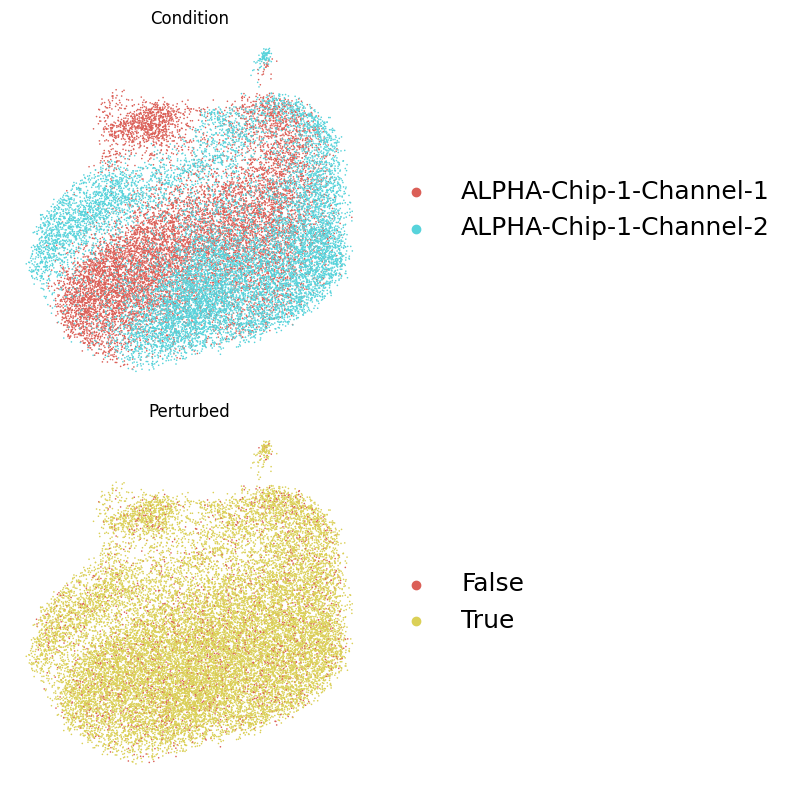

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc

fig, axes = plt.subplots(nrows=2, figsize=(8, 8))

sc.pl.umap(
    adata=adata_hvg,
    color="channel",
    legend_fontsize=18,
    ax=axes[0],
    title="Condition",
    show=False,
    palette=sns.color_palette("hls", 2),
    frameon=False
)
sc.pl.umap(
    adata=adata_hvg,
    color="perturbed",
    legend_fontsize=18,
    ax=axes[1],
    title="Perturbed",
    show=False,
    palette=sns.color_palette("hls", 7),
    frameon=False
)

# 如果你还要在第二张子图上画内容，就继续使用 axes[1]
plt.tight_layout()
plt.show()

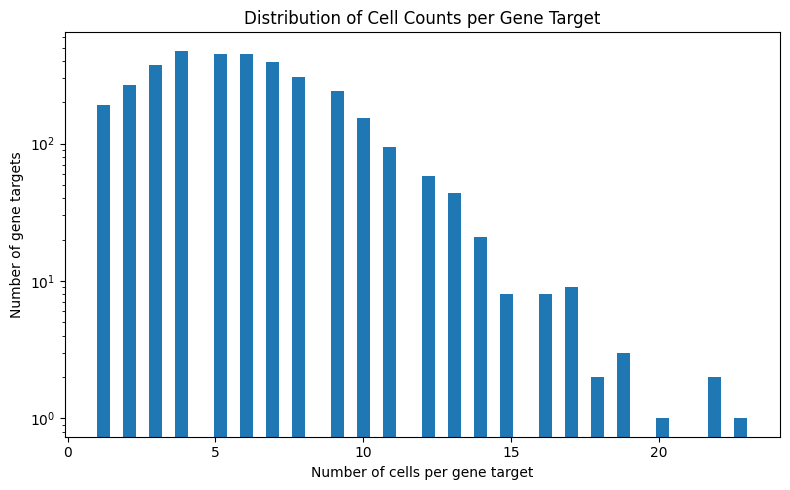

In [26]:
import matplotlib.pyplot as plt

# 排除 NTC，仅观察具体扰动靶基因的细胞数分布
counts_no_ntc = target_counts.drop(labels="NTC", errors="ignore")

plt.figure(figsize=(8, 5))
plt.hist(counts_no_ntc, bins=50)
plt.xlabel("Number of cells per gene target")
plt.ylabel("Number of gene targets")
plt.title("Distribution of Cell Counts per Gene Target")
plt.yscale("log")
plt.tight_layout()
plt.show()

In [27]:
# 统计所有 gene_target 的细胞数，包含 NTC
target_counts = adata_hvg.obs["gene_target"].value_counts(dropna=False)

print("gene_target 类别总数：", len(target_counts))
print("细胞总数：", target_counts.sum())
print("\n所有 gene_target 的细胞数：")
print(target_counts.to_string())

gene_target 类别总数： 3543
细胞总数： 22608

所有 gene_target 的细胞数：
gene_target
NTC          1856
KDM5C          23
VDR            22
ZFP41          22
ESR1           20
HNF1B          19
ZFP3           19
LARP1          19
TBXT           18
HNF4A          18
ARHGAP35       17
ADNP2          17
ZFP37          17
ELOC           17
ASNS           17
KMT5C          17
BMAL2          17
ZFP28          17
DUX4           17
ZSCAN5B        16
UBTFL1         16
TEF            16
TENT4B         16
HNF1A          16
LMNA           16
THAP12         16
BHLHE23        16
CRTC2          15
SMARCA4        15
FOXN3          15
TFB1M          15
NANOG          15
BCL6           15
ZNF354B        15
ELOB           15
ZNF280B        14
CHCHD3         14
H3-3A          14
CREBBP         14
WWC1           14
SLC27A1        14
ZNF219         14
CIPC           14
NSD2           14
BHLHA15        14
HASPIN         14
BRMS1          14
FOXO3B         14
ZFP2           14
ZNF587         14
MEIOSIN        14
KMT5B        

In [31]:
outlier_counts = adata_hvg.obs["outlier"].value_counts(dropna=False)
print(outlier_counts.to_string())
print("\noutlier 的细胞数：")


outlier
False    22608

outlier 的细胞数：


In [2]:
celltype_counts = adata_hvg.obs["celltype"].value_counts(dropna=False)
print(celltype_counts.to_string())
print("\noutlier 的细胞数：")

NameError: name 'adata_hvg' is not defined